# Homework · Repeat Purchase Prediction

Machine Learning 2026/27 · NOVA IMS · Group 41: Nicolò Boscherini, Ludovico Piras, Mattia Vannutelli

We predict `repeat_purchase_90d`, whether a customer buys again within 90 days of a purchase, for every row of `test.csv`. Kaggle scores the predictions with F1.

The final pipeline uses the cleaned data plus the month of purchase, median/mode imputation, a signed log and robust scaling, one-hot encoding, L1 feature selection and a logistic regression with an F1-tuned threshold. Honest validation F1: 0.802. Kaggle public score of these predictions: 0.804.

To run it, keep the four competition files next to this notebook, in a `data/` folder beside it, or in `data/raw/` of the project, and run all cells. It takes about two minutes and writes `Homework_Group41_submission.csv`.

<div class="alert alert-block alert-info">

# Contents<a class="anchor" id="toc"></a>
* [Setup](#setup)
* [1. Import and explore the data](#explore)
* [2. Clean and pre-process the data](#clean)
* [3. Feature selection](#selection)
* [4. Model and performance assessment](#model)

</div>

# Setup <a class="anchor" id="setup"></a>

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Expected warnings: the L1 solver stopping at max_iter, and test levels unseen in a training fold
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE = "#1779A8", "#C96A00"

RANDOM_STATE = 42
TARGET = "repeat_purchase_90d"
HORIZON = 90  # days the target looks ahead

# Competition files: next to the notebook, in data/ beside it, or in data/raw/ of the project
DATA_DIR = next((p for p in [Path("."), Path("data"), Path("../../data/raw")] if (p / "train.csv").exists()), Path("."))
OUTPUT = Path("Homework_Group41_submission.csv")

# 1. Import and explore the data <a class="anchor" id="explore"></a>
[Back to contents](#toc)

## 1.1 The files
`ID` becomes the index. The columns are grouped as in the data description of the brief. Several names are in Portuguese: `Total a Pagar` is the amount paid, `Total Bruto` the gross total, `Total Liquido` the net total, `Total Imp_` the tax, `Total Portes` the shipping, `Total Desc_` the discounts, `Custo` the cost and `N_ Detalhes` the number of invoice lines.

In [2]:
train_raw = pd.read_csv(DATA_DIR / "train.csv", index_col="ID")
test_raw = pd.read_csv(DATA_DIR / "test.csv", index_col="ID")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

GROUPS = {
    "current invoice": ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
                        "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes",
                        "invoice_count_current_purchase"],
    "current categoricals": ["payment_type", "salesperson", "commercial_zone", "transport_method",
                             "warehouse", "document_series"],
    "history: timing": ["days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count",
                        "prior_mean_gap_days", "prior_std_gap_days"],
    "history: value": ["prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                       "prior_min_purchase_value", "prior_max_purchase_value"],
    "rolling windows": [f"{kind}_{w}d" for w in [30, 90, 180, 365] for kind in ["purchase_count", "spend"]],
    "identifiers, date, decoy": ["customer_id", "purchase_date", "random_noise"],
}

print(f"train {train_raw.shape}, test {test_raw.shape}, clientes {clientes.shape}, sample {sample.shape}")
pd.DataFrame({"columns": {g: len(c) for g, c in GROUPS.items()},
              "examples": {g: ", ".join(c[:3]) for g, c in GROUPS.items()}})

train (6534, 38), test (986, 37), clientes (1143, 13), sample (986, 2)


,columns,examples
current invoice,10,"Total a Pagar, Total Bruto, Total Liquido"
current categoricals,6,"payment_type, salesperson, commercial_zone"
history: timing,5,"days_since_previous_purchase, customer_tenure_..."
history: value,5,"prior_total_spend, prior_mean_purchase_value, ..."
rolling windows,8,"purchase_count_30d, spend_30d, purchase_count_90d"
"identifiers, date, decoy",3,"customer_id, purchase_date, random_noise"


In [3]:
train_raw.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


## 1.2 The target
Predicting 1 for everybody already gives a non-trivial F1, which is the floor every model has to beat.

In [4]:
rate = train_raw[TARGET].mean()
pd.Series({"rows": len(train_raw), "share of 1 (repeat within 90 days)": round(rate, 3),
           "F1 of 'always 1'": round(f1_score(train_raw[TARGET], np.ones(len(train_raw))), 3)}).to_frame("train")

,train
rows,6534.000
share of 1 (repeat within 90 days),0.559
F1 of 'always 1',0.717


## 1.3 Data quality
Missing values, empty rows and duplicates, and values that cannot be true.

In [5]:
NUMERIC_RAW = train_raw.columns.drop([TARGET, "customer_id", "purchase_date", "random_noise",
                                      *GROUPS["current categoricals"]])
features_raw = train_raw.columns.difference([TARGET, "customer_id"])
empty = train_raw[features_raw].isna().all(axis=1)
both = pd.concat([train_raw, test_raw])

print(f"empty train rows: {empty.sum()} (test: {test_raw[features_raw].isna().all(axis=1).sum()})")
print(f"duplicated train rows: {train_raw.duplicated().sum()}, "
      f"{train_raw[~empty].duplicated().sum()} once the empty rows are removed")
first_purchase = train_raw["prior_purchase_count"] == 0
print(f"first purchases: {first_purchase.sum()}, "
      f"{train_raw.loc[first_purchase, 'days_since_previous_purchase'].isna().mean():.0%} of them "
      "without days_since_previous_purchase")
days = both[["days_since_previous_purchase", "prior_mean_gap_days"]].to_numpy()
print("values of the negative day intervals:", np.unique(days[days < 0]))

quality = pd.DataFrame({
    "missing train %": train_raw.drop(columns=TARGET)[~empty].isna().mean() * 100,
    "missing test %": test_raw.isna().mean() * 100,
    "negative (train+test)": both[NUMERIC_RAW].lt(0).sum(),
    ">= 1e9 (train+test)": both[NUMERIC_RAW].ge(1e9).sum(),
}).fillna(0)
quality[quality.sum(axis=1) > 0].sort_values("missing train %", ascending=False).round(1)

empty train rows: 65 (test: 0)
duplicated train rows: 10, 0 once the empty rows are removed
first purchases: 603, 100% of them without days_since_previous_purchase
values of the negative day intervals: [-4.]


,missing train %,missing test %,negative (train+test),>= 1e9 (train+test)
prior_std_gap_days,21.8,7.0,0.0,0.0
prior_mean_gap_days,19.2,7.7,18.0,0.0
prior_std_purchase_value,16.2,4.7,0.0,0.0
prior_mean_purchase_value,12.3,5.3,18.0,18.0
days_since_previous_purchase,12.3,5.3,18.0,0.0
prior_max_purchase_value,9.3,2.2,0.0,0.0
prior_min_purchase_value,9.3,2.2,0.0,0.0
transport_method,3.0,3.0,0.0,0.0
payment_type,3.0,3.0,0.0,0.0
spend_365d,3.0,3.0,17.0,17.0


**Consistency checks.** Several columns are tied by arithmetic: the invoice totals, the history statistics, and the rolling windows, which are nested (30 ⊂ 90 ⊂ 180 ⊂ 365 days). Share of the rows where each relation holds, on train and test together, with the impossible values above hidden.

In [6]:
labelled = train_raw[~empty]
checked = both[NUMERIC_RAW].mask((both[NUMERIC_RAW] < 0) | (both[NUMERIC_RAW] >= 1e9))
count, total, tenure = checked["prior_purchase_count"], checked["prior_total_spend"], checked["customer_tenure_days"]
RELATIONS = {  # name: (rows where it applies, left side, right side)
    "Bruto - discounts = Liquido": (count.notna(), checked["Total Bruto"] - checked["Total Desc_ Linha"]
                                    - checked["Total Desc_ Global"], checked["Total Liquido"]),
    "Liquido + Imp_ = a Pagar": (count.notna(), checked["Total Liquido"] + checked["Total Imp_"], checked["Total a Pagar"]),
    "mean purchase = total / count": (count >= 1, checked["prior_mean_purchase_value"], total / count.where(count > 0)),
    "max purchase = total (count = 1)": (count == 1, checked["prior_max_purchase_value"], total),
    "days since = tenure (count = 1)": (count == 1, checked["days_since_previous_purchase"], tenure),
    "tenure - days since = (count-1) x gap": (count >= 2, tenure - checked["days_since_previous_purchase"],
                                              (count - 1) * checked["prior_mean_gap_days"]),
    "spend 365d = spend 180d (same counts)": (checked["purchase_count_365d"] == checked["purchase_count_180d"],
                                             checked["spend_365d"], checked["spend_180d"]),
}
rows = {}
for name, (applies, left, right) in RELATIONS.items():
    complete = applies & left.notna() & right.notna()
    rows[name] = {"rows checked": int(complete.sum()),
                  "share where it holds": np.isclose(left[complete], right[complete], rtol=1e-4, atol=0.05).mean()}
for short, long in zip([30, 90, 180], [90, 180, 365]):
    pair = checked[[f"purchase_count_{short}d", f"purchase_count_{long}d"]].dropna()
    rows[f"purchase_count_{short}d <= purchase_count_{long}d"] = {
        "rows checked": len(pair), "share where it holds": (pair.iloc[:, 0] <= pair.iloc[:, 1]).mean()}
pd.DataFrame(rows).T.astype({"rows checked": int}).style.format({"share where it holds": "{:.2%}"})

,rows checked,share where it holds
Bruto - discounts = Liquido,7455,100.00%
Liquido + Imp_ = a Pagar,7455,100.00%
mean purchase = total / count,6570,99.19%
max purchase = total (count = 1),469,99.36%
days since = tenure (count = 1),446,100.00%
tenure - days since = (count-1) x gap,5908,100.00%
spend 365d = spend 180d (same counts),1915,99.48%
purchase_count_30d <= purchase_count_90d,7455,100.00%
purchase_count_90d <= purchase_count_180d,7455,100.00%
purchase_count_180d <= purchase_count_365d,7455,100.00%


65 train rows are empty apart from `customer_id` and the target, and they are also the source of all 10 duplicates. Most of the missing values in the history columns are structural: the 603 first purchases have no previous gap or purchase value. Test has fewer of them because only 2% of its rows are first purchases, against 9% in train. The rest is scattered across both files: about 3% of the categoricals and of `spend_365d`, and a few history cells. Some values cannot be real: day intervals of exactly −4 and amounts of 10⁹ look like placeholders, and a few amounts are negative.

The arithmetic between columns is otherwise clean. The invoice identities and the nesting of the rolling windows hold on every row, and the history identities on more than 99% of them; the few exceptions are corrupted values (a mean purchase that does not match total ÷ count, a maximum purchase or a 365-day spend above the total spend). Section 2 deals with all of these, and uses the identities to rebuild lost values.

## 1.4 Time and repeated customers
The dates are anonymised, but their order and the intervals between them are preserved.

train: 2015-07-11 -> 2025-02-15
test:  2025-05-24 -> 2026-10-06   (gap of 98 days after train)
customers: 610 in train, 206 in test; 94.5% of test rows belong to a train customer


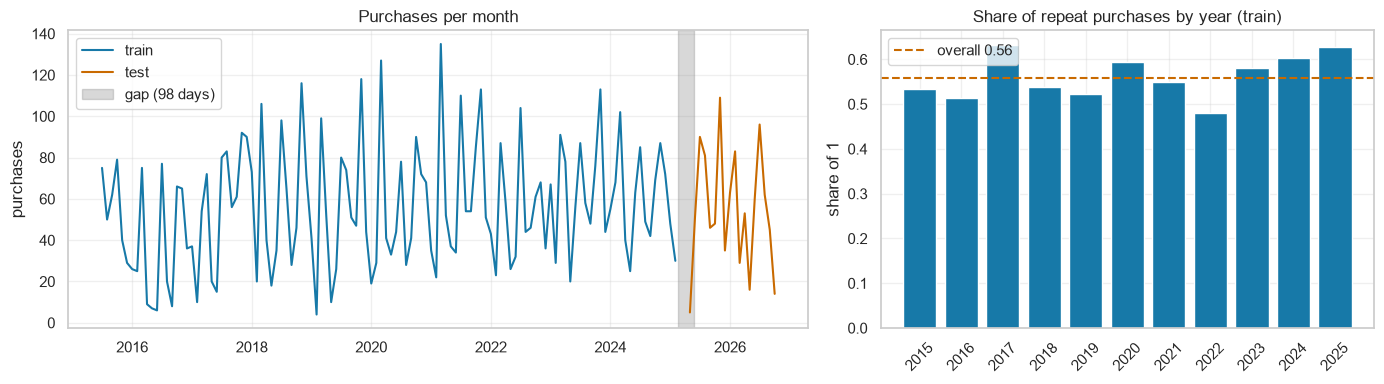

In [7]:
dates_train = pd.to_datetime(train_raw["purchase_date"])
dates_test = pd.to_datetime(test_raw["purchase_date"])
gap = (dates_test.min() - dates_train.max()).days
print(f"train: {dates_train.min():%Y-%m-%d} -> {dates_train.max():%Y-%m-%d}")
print(f"test:  {dates_test.min():%Y-%m-%d} -> {dates_test.max():%Y-%m-%d}   (gap of {gap} days after train)")
print(f"customers: {train_raw['customer_id'].nunique()} in train, {test_raw['customer_id'].nunique()} in test; "
      f"{test_raw['customer_id'].isin(train_raw['customer_id']).mean():.1%} of test rows belong to a train customer")

monthly = pd.DataFrame({"train": dates_train.dt.to_period("M").value_counts(),
                        "test": dates_test.dt.to_period("M").value_counts()}).sort_index()
monthly.index = monthly.index.to_timestamp()
by_year = train_raw.groupby(dates_train.dt.year)[TARGET].agg(["mean", "size"])

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 2]})
left.plot(monthly.index, monthly["train"], color=BLUE, label="train")
left.plot(monthly.index, monthly["test"], color=ORANGE, label="test")
left.axvspan(dates_train.max(), dates_test.min(), color="grey", alpha=0.3, label=f"gap ({gap} days)")
left.set(title="Purchases per month", ylabel="purchases")
left.legend()
right.bar(by_year.index.astype(int).astype(str), by_year["mean"], color=BLUE)
right.axhline(rate, color=ORANGE, ls="--", label=f"overall {rate:.2f}")
right.set(title="Share of repeat purchases by year (train)", ylabel="share of 1")
right.tick_params(axis="x", rotation=45)
right.legend()
plt.tight_layout()
plt.show()

Inside train, the target can be checked against each customer's next purchase.

In [8]:
# Days from each train purchase to the same customer's next row
ordered = labelled.assign(date=dates_train).sort_values(["customer_id", "date"])
next_gap = ordered.groupby("customer_id")["date"].shift(-1).sub(ordered["date"]).dt.days
has_next = next_gap.notna()
matches = (next_gap[has_next] <= HORIZON).astype(int) == ordered.loc[has_next, TARGET]
print(f"target equals 'next row within 90 days' in {matches.mean():.1%} of the train rows")

target equals 'next row within 90 days' in 99.7% of the train rows


Test comes entirely after train, 98 days later, so we are predicting the future and the validation has to respect that (Section 2.6). The monthly volume is very irregular, and the repeat rate moves between 0.48 and 0.63 from one year to the next. 94.5% of the test rows belong to customers already seen in train.

The target is simply the customer's next purchase: in 99.7% of the train rows it matches "another row of the same customer within 90 days". For this reason every feature in the notebook uses only what is known at the time of the purchase. Reading a customer's later rows would give the answer away.

## 1.5 Univariate view
Summary statistics of every numeric column (impossible values hidden, for exploration only), the effect of a log on two typical columns, and the categorical levels.

In [9]:
valid = labelled[NUMERIC_RAW].mask((labelled[NUMERIC_RAW] < 0) | (labelled[NUMERIC_RAW] >= 1e9))
summary = valid.describe().T[["mean", "50%", "min", "max"]].rename(columns={"50%": "median"})
summary["skewness"] = valid.skew()
summary["% zeros"] = 100 * valid.eq(0).mean()
summary.sort_values("skewness", ascending=False).round(2)

,mean,median,min,max,skewness,% zeros
Total Desc_ Global,0.35,0.00,0.00,218.49,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,3.31,267526.19,21.34,0.00
prior_mean_purchase_value,957.93,724.90,3.31,72937.16,21.20,0.00
Total Portes,1.15,0.00,0.00,181.06,19.55,83.72
spend_365d,5777.74,2426.60,0.00,522933.21,18.55,12.52
prior_mean_gap_days,96.18,68.61,1.00,3199.00,9.31,0.00
prior_std_gap_days,74.14,50.64,0.00,2212.54,7.77,0.02
days_since_previous_purchase,101.83,57.00,1.00,3199.00,6.53,0.00
invoice_count_current_purchase,1.07,1.00,1.00,5.00,6.44,0.00
Total Desc_ Linha,112.47,13.13,0.00,4103.44,5.92,37.73


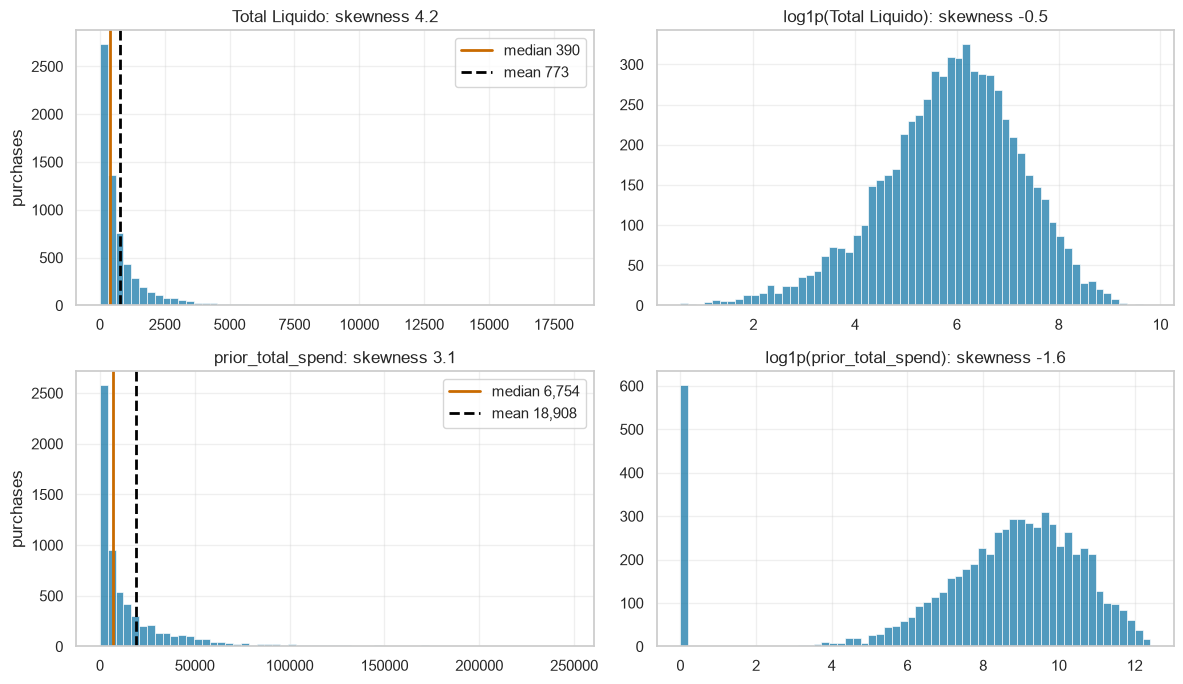

train rows with at least one value outside 1.5 x IQR: 66%; their repeat rate 0.60 vs 0.47 for the others


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, column in enumerate(["Total Liquido", "prior_total_spend"]):
    values = valid[column].dropna()
    sns.histplot(values, bins=60, color=BLUE, ax=axes[row, 0])
    axes[row, 0].axvline(values.median(), color=ORANGE, lw=2, label=f"median {values.median():,.0f}")
    axes[row, 0].axvline(values.mean(), color="black", ls="--", lw=2, label=f"mean {values.mean():,.0f}")
    axes[row, 0].set(title=f"{column}: skewness {values.skew():.1f}", xlabel="", ylabel="purchases")
    axes[row, 0].legend()
    sns.histplot(np.log1p(values), bins=60, color=BLUE, ax=axes[row, 1])
    axes[row, 1].set(title=f"log1p({column}): skewness {np.log1p(values).skew():.1f}", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# Outliers by the 1.5 x IQR rule, on the raw scale
q1, q3 = valid.quantile(0.25), valid.quantile(0.75)
flagged = ((valid < q1 - 1.5 * (q3 - q1)) | (valid > q3 + 1.5 * (q3 - q1))).any(axis=1)
print(f"train rows with at least one value outside 1.5 x IQR: {flagged.mean():.0%}; "
      f"their repeat rate {labelled.loc[flagged, TARGET].mean():.2f} vs {labelled.loc[~flagged, TARGET].mean():.2f} for the others")

In [11]:
CATEGORICAL = GROUPS["current categoricals"]
pd.DataFrame({
    "levels in train": train_raw[CATEGORICAL].nunique(),
    "top level share": train_raw[CATEGORICAL].apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "levels with < 50 rows": train_raw[CATEGORICAL].apply(lambda s: (s.value_counts() < 50).sum()),
    "test rows with a level unseen in train": [(~test_raw[c].dropna().isin(train_raw[c])).sum() for c in CATEGORICAL],
}).round(2)

,levels in train,top level share,levels with < 50 rows,test rows with a level unseen in train
payment_type,9,0.73,5,3
salesperson,9,0.65,4,0
commercial_zone,5,0.97,2,209
transport_method,80,0.18,57,63
warehouse,2,1.00,1,7
document_series,3,0.42,0,0


Almost every numeric column is right-skewed, with the mean well above the median (skewness up to 27), and several are mostly zeros: global discounts in 98% of the rows, shipping in 84%. A log removes most of the skew, as the two examples show. The 1.5 × IQR rule flags 66% of the train rows, and those rows repeat more often than the others (0.60 against 0.47): the extreme values are large, frequent customers rather than errors.

Among the categoricals, `warehouse` and `commercial_zone` are almost constant, `transport_method` has 80 levels (57 of them with fewer than 50 rows), and 209 test rows have a `commercial_zone` that never appears in train.

## 1.6 Relationships with the target
Spearman correlation for the numeric columns, the strongest of them by class, Cramér's V for the categorical columns, the repeat rate by month, and the correlations between columns.

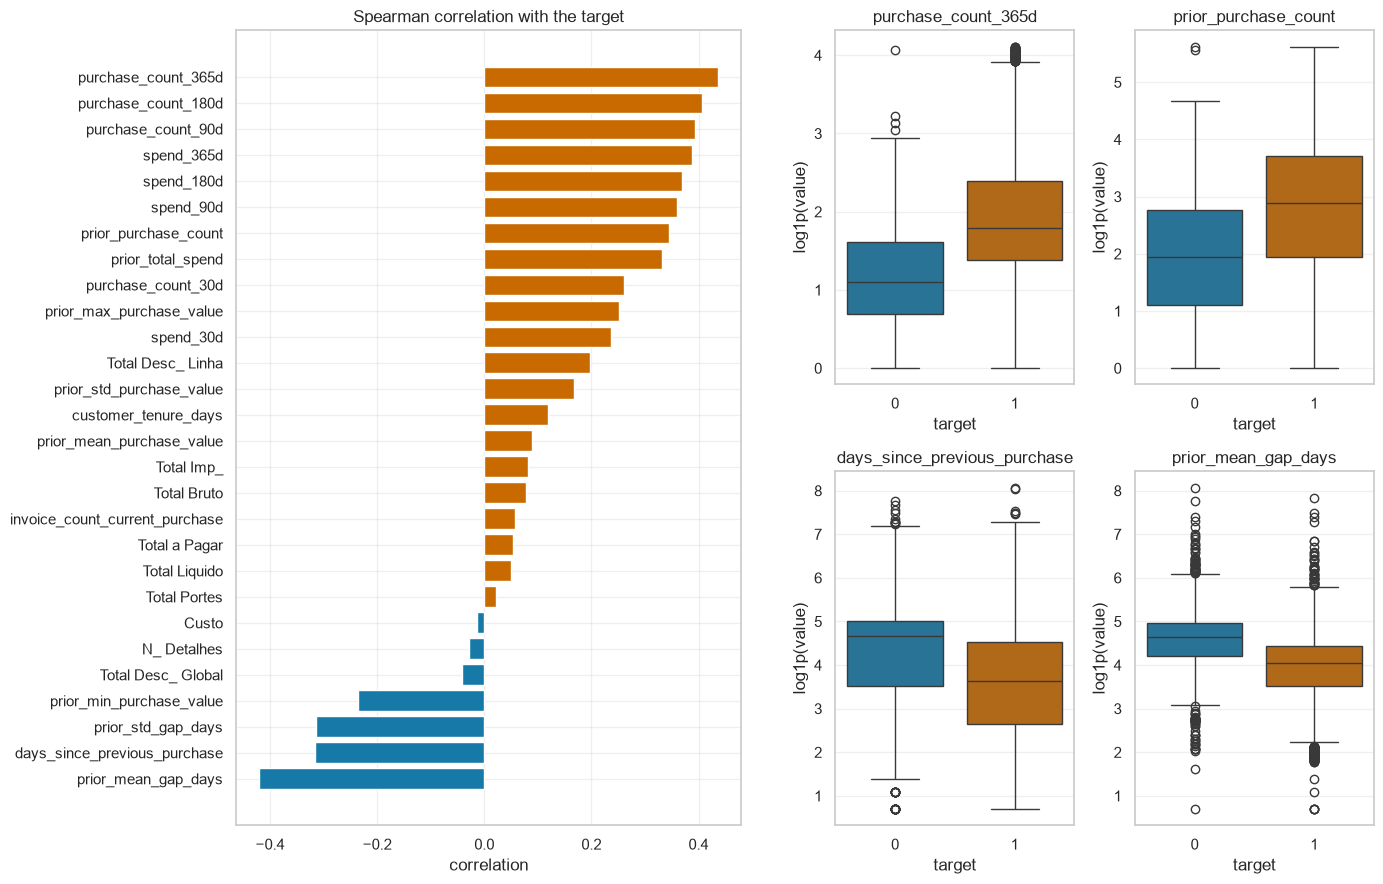

In [12]:
spearman = valid.corrwith(labelled[TARGET], method="spearman").sort_values()
KEY = ["purchase_count_365d", "prior_purchase_count", "days_since_previous_purchase", "prior_mean_gap_days"]

fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(1, 2, 1)
ax.barh(spearman.index, spearman, color=np.where(spearman > 0, ORANGE, BLUE))
ax.set(title="Spearman correlation with the target", xlabel="correlation")
for i, column in enumerate(KEY):
    ax = fig.add_subplot(2, 4, 3 + i + 2 * (i >= 2))
    sns.boxplot(x=labelled[TARGET], y=np.log1p(valid[column]), hue=labelled[TARGET],
                palette={0: BLUE, 1: ORANGE}, legend=False, ax=ax)
    ax.set(title=column, ylabel="log1p(value)", xlabel="target")
plt.tight_layout()
plt.show()

,Cramér's V with target
transport_method,0.285
payment_type,0.234
salesperson,0.201
commercial_zone,0.064
warehouse,0.040
document_series,0.003


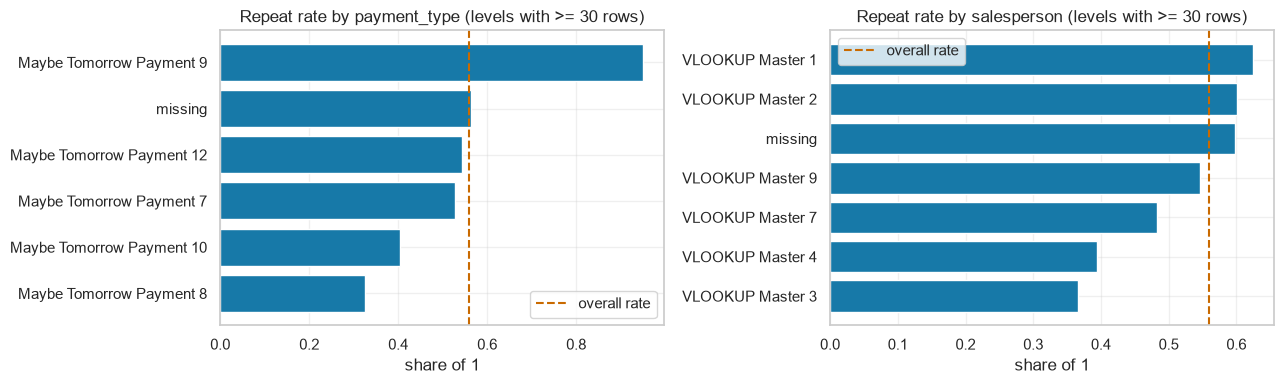

In [13]:
def cramers_v(x, y):
    """Association between two categorical variables: 0 = none, 1 = perfect."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


cramer = pd.Series({c: cramers_v(labelled[c].fillna("missing"), labelled[TARGET]) for c in CATEGORICAL}
                   ).sort_values(ascending=False)
display(cramer.round(3).to_frame("Cramér's V with target"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(axes, ["payment_type", "salesperson"]):
    by_level = (labelled.assign(level=labelled[column].fillna("missing"))
                .groupby("level")[TARGET].agg(["mean", "size"]).query("size >= 30").sort_values("mean"))
    ax.barh(by_level.index, by_level["mean"], color=BLUE)
    ax.axvline(rate, color=ORANGE, ls="--", label="overall rate")
    ax.set(title=f"Repeat rate by {column} (levels with >= 30 rows)", xlabel="share of 1")
    ax.legend()
plt.tight_layout()
plt.show()

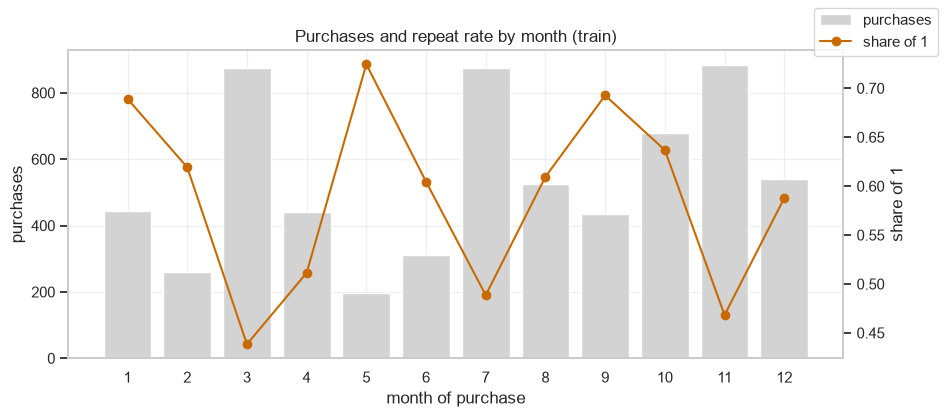

In [14]:
month = dates_train.dt.month
by_month = train_raw.groupby(month)[TARGET].agg(["mean", "size"])
fig, ax1 = plt.subplots()
ax1.bar(by_month.index, by_month["size"], color="lightgrey", label="purchases")
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["mean"], color=ORANGE, marker="o", label="share of 1")
ax1.set(xticks=range(1, 13), xlabel="month of purchase", ylabel="purchases",
        title="Purchases and repeat rate by month (train)")
ax2.set_ylabel("share of 1")
ax2.grid(False)
fig.legend(loc="upper right")
plt.show()

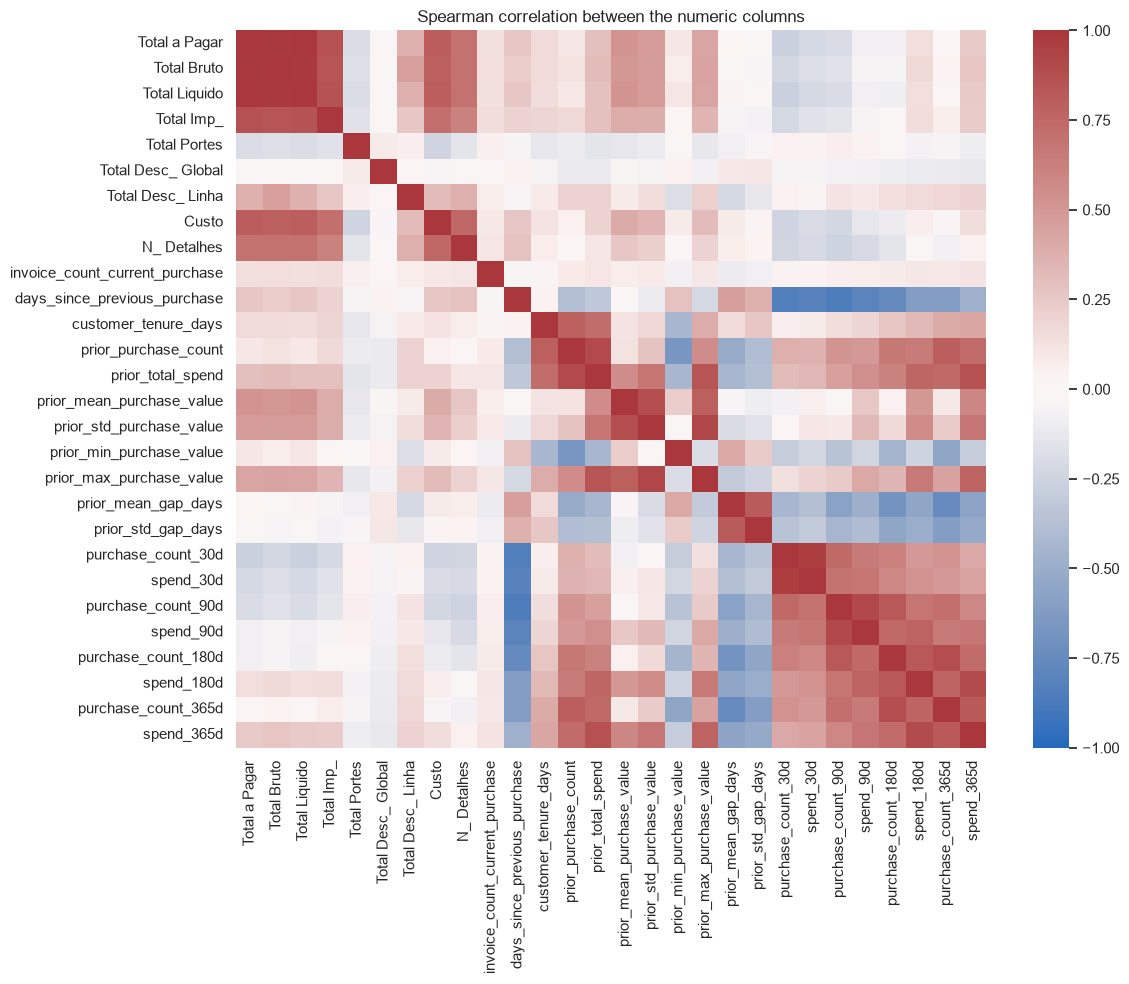

,,|Spearman|
Total a Pagar,Total Liquido,1.000
Total Bruto,Total Liquido,0.991
Total a Pagar,Total Bruto,0.991
purchase_count_30d,spend_30d,0.965
prior_std_purchase_value,prior_max_purchase_value,0.923
purchase_count_90d,spend_90d,0.909
prior_purchase_count,prior_total_spend,0.903


In [15]:
corr = valid.corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Spearman correlation between the numeric columns")
plt.tight_layout()
plt.show()

pairs = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs >= 0.9].sort_values(ascending=False).round(3).to_frame("|Spearman|")

Frequency and rhythm carry most of the signal. Purchases in the last 365, 180 and 90 days go up with the target (Spearman around 0.4) and the usual gap between purchases goes down (−0.42); the box plots show the two classes clearly apart on these columns. The amounts of the current invoice are almost unrelated to the target.

Among the categoricals, `transport_method`, `payment_type` and `salesperson` show some association (V between 0.20 and 0.29), `document_series` none. One payment type stands out: `Maybe Tomorrow Payment 9` is followed by a repeat 95% of the time (502 rows).

The repeat rate follows a 4-month cycle. March, July and November have the most purchases and the lowest repeat rate, while the months two months before each peak have the highest: a purchase in a peak month is usually followed by the next peak, more than 90 days later. This is why we test the month as a feature.

Many columns are near-copies of each other (|ρ| ≥ 0.9): the invoice totals, each rolling count and its spend, the purchase count and the total spend. That is a job for feature selection.

## 1.7 Identifier-like columns and `random_noise`
ROC AUC of each column used alone as a score (0.5 means no information) and its correlation with time. The decisions are in Section 3.1.

In [16]:
ident = labelled.assign(ID=labelled.index, date_order=dates_train[~empty].rank())
columns = ["ID", "customer_id", "random_noise"]
pd.DataFrame({
    "ROC AUC alone vs target": {c: roc_auc_score(ident[TARGET], ident[c].fillna(ident[c].median())) for c in columns},
    "Spearman with date": {c: ident[c].corr(ident["date_order"], method="spearman") for c in columns},
}).round(3)

,ROC AUC alone vs target,Spearman with date
ID,0.507,0.011
customer_id,0.433,-0.022
random_noise,0.495,0.018


## 1.8 The optional `clientes.csv`

1143 customers; every train and test customer is in the table: True


,missing %,distinct values
customer_id,0.0,1143
country_or_region,0.0,11
commercial_region,10.0,37
island,50.6,10
municipality,13.9,183
city,47.8,417
postal_area,6.2,271
postal_code,14.9,828
street,52.3,511
address,0.5,1120


customer_since_year later than the first recorded purchase: 0.0
Spearman with target: customer_since_year -0.111 | customer_tenure_days 0.12


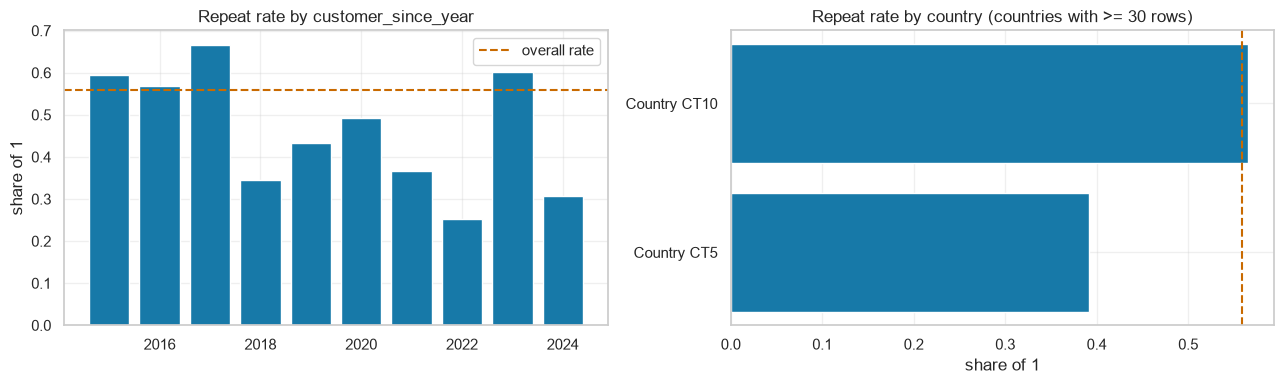

In [17]:
matched = (train_raw["customer_id"].isin(clientes["customer_id"]).all()
           and test_raw["customer_id"].isin(clientes["customer_id"]).all())
print(f"{clientes['customer_id'].nunique()} customers; every train and test customer is in the table: {matched}")
display(pd.DataFrame({"missing %": clientes.isna().mean() * 100, "distinct values": clientes.nunique()}).round(1))

joined = labelled.join(clientes.set_index("customer_id"), on="customer_id")
first_year = (dates_train[~empty] - pd.to_timedelta(labelled["customer_tenure_days"], unit="D")).dt.year
print("customer_since_year later than the first recorded purchase:", (joined["customer_since_year"] > first_year).mean())
print("Spearman with target: customer_since_year",
      joined["customer_since_year"].corr(joined[TARGET], method="spearman").round(3),
      "| customer_tenure_days", joined["customer_tenure_days"].corr(joined[TARGET], method="spearman").round(3))

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
by_since = joined.groupby("customer_since_year")[TARGET].agg(["mean", "size"])
left.bar(by_since.index, by_since["mean"], color=BLUE)
left.axhline(rate, color=ORANGE, ls="--", label="overall rate")
left.set(title="Repeat rate by customer_since_year", ylabel="share of 1")
left.legend()
by_country = joined.groupby("country_or_region")[TARGET].agg(["mean", "size"]).query("size >= 30").sort_values("mean")
right.barh(by_country.index.str.split(":").str[0], by_country["mean"], color=BLUE)
right.axvline(rate, color=ORANGE, ls="--")
right.set(title="Repeat rate by country (countries with >= 30 rows)", xlabel="share of 1")
plt.tight_layout()
plt.show()

Every customer is in the table, but most columns are of little use: `customer_type` is empty, `company_name` and `address` are unique per customer, and the geography below country level is fragmented and often missing. Country and `customer_since_year` are the plausible candidates. Older customers repeat more (57–67% for those since 2015–2017, mostly 25–49% afterwards), and the second country repeats less than the first, but it has few rows. `customer_since_year` is never later than the first recorded purchase, so it does not leak, yet it says roughly what `customer_tenure_days` already says. Both are tested in Section 2.8.

## 1.9 From the exploration to the pipeline

| Finding | Action |
|---|---|
| 65 empty train rows, the cause of all duplicates | drop them from train |
| placeholders (−4 days, 10⁹) and negative amounts | rule-based: impossible value → missing |
| exact identities between columns | rebuild lost values instead of imputing them |
| structural and scattered missing values | imputation inside the pipeline |
| strong skew, many zeros | signed log and robust scaling for the linear models |
| extreme values belong to large, frequent customers | no rows removed as outliers |
| dominant, rare and unseen categorical levels | one-hot with rare levels grouped |
| 4-month cycle in the repeat rate | month of purchase as a candidate feature |
| many near-duplicate columns | feature selection |
| `ID` and `random_noise` carry no information; `customer_id` only identifies the customer | not used as features |
| test is later than train, the repeat rate drifts, the target looks 90 days ahead | time-ordered validation with a 90-day gap; features use only the past |

# 2. Clean and pre-process the data <a class="anchor" id="clean"></a>
[Back to contents](#toc)

Cleaning (2.1–2.5) uses fixed rules, the same for train and test, so it learns nothing from the data. Everything that does learn (imputation, scaling, encoding, selection, the model) sits in a scikit-learn pipeline and is refitted on the training rows of each fold.

## 2.1 Names and types
English names for the Portuguese invoice columns, a proper date type and stripped labels.

In [18]:
COLUMN_MAP = {
    "Total a Pagar": "total_to_pay",        # amount paid by the customer = net + tax
    "Total Bruto": "total_gross",           # before discounts
    "Total Liquido": "total_net",           # after discounts, before tax
    "Total Imp_": "total_tax",              # VAT
    "Total Portes": "total_shipping",       # shipping (not part of total_to_pay)
    "Total Desc_ Global": "discount_global",
    "Total Desc_ Linha": "discount_line",
    "Custo": "cost",                        # cost of goods for the company
    "N_ Detalhes": "n_lines",               # number of product lines on the invoice
}
WINDOWS = [30, 90, 180, 365]
DAY_COLS = ["days_since_previous_purchase", "customer_tenure_days", "prior_mean_gap_days", "prior_std_gap_days"]
COUNT_COLS = ["n_lines", "invoice_count_current_purchase", "prior_purchase_count"] + [f"purchase_count_{w}d" for w in WINDOWS]
AMOUNT_COLS = (["total_to_pay", "total_gross", "total_net", "total_tax", "total_shipping", "discount_global",
                "discount_line", "cost", "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                "prior_min_purchase_value", "prior_max_purchase_value"] + [f"spend_{w}d" for w in WINDOWS])
PLACEHOLDER = 1e9  # value used in the raw data in place of a real amount
TOL = 0.01         # one cent / a hundredth of a day: tolerance for float comparisons


def rename_and_type(df):
    """English snake_case names, datetime date, stripped string categoricals."""
    df = df.rename(columns=COLUMN_MAP)
    df["purchase_date"] = pd.to_datetime(df["purchase_date"])
    for col in CATEGORICAL:
        df[col] = df[col].astype("str").str.strip()
    return df

## 2.2 Empty rows
The 65 empty rows are removed from train only. Test has none, and no test row is ever removed.

In [19]:
def drop_empty_rows(df):
    """Remove rows where every feature is missing. Returns the frame and the number dropped."""
    features = df.columns.difference([TARGET, "customer_id"])
    is_empty = df[features].isna().all(axis=1)
    return df[~is_empty], int(is_empty.sum())

## 2.3 Impossible values become missing
Negative day intervals, counts or amounts; amounts of 10⁹ or more; a mean purchase that differs from total ÷ count; a maximum purchase or a 365-day spend above the total spend; a 365-day spend below the 180-day one.

In [20]:
def invalid_value_rules(df):
    """List of (rule, column, mask). True in the mask = impossible value, to be set to NaN."""
    rules = []
    for col in DAY_COLS:
        rules.append(("negative day interval", col, df[col] < 0))
    for col in COUNT_COLS:
        rules.append(("negative count", col, df[col] < 0))
    for col in AMOUNT_COLS:
        rules.append(("placeholder 1e9", col, df[col] >= PLACEHOLDER))
        rules.append(("negative amount", col, df[col] < 0))
    mean, total, count = df["prior_mean_purchase_value"], df["prior_total_spend"], df["prior_purchase_count"]
    expected_mean = total / count.where(count > 0)
    rules.append(("mean != total / count", "prior_mean_purchase_value",
                  expected_mean.notna() & ~np.isclose(mean, expected_mean, rtol=1e-4, atol=TOL)))
    rules.append(("max > total spend", "prior_max_purchase_value", df["prior_max_purchase_value"] > total + TOL))
    rules.append(("365d spend > total spend", "spend_365d", df["spend_365d"] > total + TOL))
    rules.append(("365d spend < 180d spend", "spend_365d", df["spend_365d"] < df["spend_180d"] - TOL))
    return rules


def set_invalid_to_nan(df):
    """Apply every rule in order; the log counts only cells that were not already NaN."""
    df = df.copy()
    log = []
    for rule, col, mask in invalid_value_rules(df):
        hit = mask & df[col].notna()
        df.loc[hit, col] = np.nan
        log.append((rule, col, int(hit.sum())))
    return df, pd.DataFrame(log, columns=["rule", "column", "cells"])

## 2.4 Rebuilding values from exact identities
The history identities checked in Section 1.3 (for example mean = total ÷ count) hold on more than 99% of the rows. Where one side is missing, or was set to missing in 2.3, we rebuild it instead of imputing it.

In [21]:
def rebuild_from_identities(df):
    """Fill NaNs that an exact identity gives back. Returns the frame and a log of cells filled."""
    df = df.copy()
    log = []

    def fill(col, rule, values, applies):
        hit = df[col].isna() & applies & values.notna()
        df.loc[hit, col] = values[hit]
        log.append((rule, col, int(hit.sum())))

    count, total, tenure = df["prior_purchase_count"], df["prior_total_spend"], df["customer_tenure_days"]
    fill("prior_mean_purchase_value", "total / count", total / count.where(count > 0), count >= 1)
    fill("prior_max_purchase_value", "max = total (count = 1)", total, count == 1)
    fill("days_since_previous_purchase", "days since = tenure (count = 1)", tenure, count == 1)
    fill("days_since_previous_purchase", "tenure - (count-1) x gap",
         (tenure - (count - 1) * df["prior_mean_gap_days"]).round(), count >= 2)
    fill("prior_mean_gap_days", "(tenure - days since) / (count-1)",
         (tenure - df["days_since_previous_purchase"]) / (count - 1), count >= 2)
    fill("spend_365d", "spend 365d = spend 180d (same counts)", df["spend_180d"],
         df["purchase_count_365d"] == df["purchase_count_180d"])
    fill("spend_365d", "spend 365d = total (all in 365d)", total, df["purchase_count_365d"] == count)
    return df, pd.DataFrame(log, columns=["rule", "column", "cells"])

## 2.5 Cleaning train and test
Number of cells changed by each rule in each file.

In [22]:
def clean(df):
    """Deterministic cleaning, identical for train and test. Never drops rows."""
    df = rename_and_type(df)
    df, _ = set_invalid_to_nan(df)
    df, _ = rebuild_from_identities(df)
    return df


train_kept, n_empty = drop_empty_rows(train_raw)
train = clean(train_kept)
test = clean(test_raw)

logs = {}
for name, frame in [("train", rename_and_type(train_kept)), ("test", rename_and_type(test_raw))]:
    invalid, log_invalid = set_invalid_to_nan(frame)
    _, log_rebuilt = rebuild_from_identities(invalid)
    logs[name] = pd.concat([log_invalid.assign(step="impossible -> NaN"), log_rebuilt.assign(step="rebuilt")])
changes = logs["train"].merge(logs["test"], on=["step", "rule", "column"], suffixes=(" train", " test"))
display(changes[changes[["cells train", "cells test"]].sum(axis=1) > 0].set_index(["step", "rule", "column"]))
print(f"train {train_raw.shape} -> {train.shape} ({n_empty} empty rows dropped); test {test_raw.shape} -> {test.shape}")

cells train  \
step              rule                                  column                                      
impossible -> NaN negative day interval                 days_since_previous_purchase           16   
                                                        prior_mean_gap_days                    16   
                  placeholder 1e9                       prior_mean_purchase_value              16   
                  negative amount                       prior_mean_purchase_value              16   
                  placeholder 1e9                       spend_365d                             15   
                  negative amount                       spend_365d                             15   
                  mean != total / count                 prior_mean_purchase_value              46   
                  max > total spend                     prior_max_purchase_value               45   
                  365d spend > total spend              spend_365d                             39   
rebuilt           total / count                         prior_mean_purchase_value             272   
                  max = total (count = 1)               prior_max_purchase_value                3   
                  days since = tenure (count = 1)       days_since_previous_purchase           22   
                  tenure - (count-1) x gap              days_since_previous_purchase          179   
                  (tenure - days since) / (count-1)     prior_mean_gap_days                   203   
                  spend 365d = spend 180d (same counts) spend_365d                             80   
                  spend 365d = total (all in 365d)      spend_365d                             28   

                                                                                      cells test  
step              rule                                  column                                    
impossible -> NaN negative day interval                 days_since_previous_purchase           2  
                                                        prior_mean_gap_days                    2  
                  placeholder 1e9                       prior_mean_purchase_value              2  
                  negative amount                       prior_mean_purchase_value              2  
                  placeholder 1e9                       spend_365d                             2  
                  negative amount                       spend_365d                             2  
                  mean != total / count                 prior_mean_purchase_value              7  
                  max > total spend                     prior_max_purchase_value               6  
                  365d spend > total spend              spend_365d                             7  
rebuilt           total / count                         prior_mean_purchase_value             41  
                  max = total (count = 1)               prior_max_purchase_value               0  
                  days since = tenure (count = 1)       days_since_previous_purchase           1  
                  tenure - (count-1) x gap              days_since_previous_purchase          31  
                  (tenure - days since) / (count-1)     prior_mean_gap_days                   32  
                  spend 365d = spend 180d (same counts) spend_365d                             4  
                  spend 365d = total (all in 365d)      spend_365d                             1

train (6534, 38) -> (6469, 38) (65 empty rows dropped); test (986, 37) -> (986, 37)


## 2.6 Validation scheme
All the decisions below are made on the same time-ordered cross-validation: three yearly validation blocks (2022, 2023, and 2024 to February 2025), each trained only on purchases made more than 90 days before the block starts, as in the real gap between train and test. Pipelines are compared fold by fold on ROC AUC.

In [23]:
X_full = train.drop(columns=[TARGET])  # identifiers and date are needed to build features, then dropped
y = train[TARGET]
X_test_full = test.copy()
ALWAYS_DROP = ["customer_id", "purchase_date", "random_noise"]


def time_splits(dates, val_starts, gap_days=HORIZON):
    """Expanding-window splits: fold k validates on [start_k, start_k+1) and trains on rows before start_k - gap."""
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    starts = list(pd.to_datetime(val_starts)) + [dates.max() + pd.Timedelta(days=1)]
    for start, end in zip(starts[:-1], starts[1:]):
        yield (np.flatnonzero(dates < start - pd.Timedelta(days=gap_days)),
               np.flatnonzero((dates >= start) & (dates < end)))


FOLDS = list(time_splits(X_full["purchase_date"], ["2022-01-01", "2023-01-01", "2024-01-01"]))


def evaluate(model, splits=FOLDS, X=X_full):
    """Refit a fresh copy on each training fold. Returns per-fold ROC AUC and the out-of-fold probabilities."""
    aucs, oof = [], pd.Series(np.nan, index=y.index)
    for tr, va in splits:
        proba = clone(model).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
        oof.iloc[va] = proba
        aucs.append(roc_auc_score(y.iloc[va], proba))
    return np.array(aucs), oof


def compare(pipelines, reference):
    """ROC AUC of each pipeline and its difference from the reference, fold by fold."""
    scores = {name: evaluate(p)[0] for name, p in pipelines.items()}
    rows = {}
    for name, s in scores.items():
        diff = s - scores[reference]
        rows[name] = {"ROC AUC": s.mean(), "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in s),
                      "diff vs reference": diff.mean(), "folds better": f"{(diff > 0).sum()}/{len(s)}"}
    return pd.DataFrame(rows).T.sort_values("ROC AUC", ascending=False)


pd.DataFrame([{"fold": k + 1, "train rows": len(tr),
               "train until": f"{X_full['purchase_date'].iloc[tr].max():%Y-%m-%d}",
               "validation": f"{X_full['purchase_date'].iloc[va].min():%Y-%m-%d} -> "
                             f"{X_full['purchase_date'].iloc[va].max():%Y-%m-%d}",
               "validation rows": len(va), "share of 1": y.iloc[va].mean().round(3)}
              for k, (tr, va) in enumerate(FOLDS)]).set_index("fold")

,train rows,train until,validation,validation rows,share of 1
fold,,,,,
1,4004,2021-10-02,2022-01-01 -> 2022-12-29,628,0.481
2,4705,2022-10-02,2023-01-01 -> 2023-12-31,767,0.581
3,5403,2023-10-02,2024-01-01 -> 2025-02-15,835,0.605


## 2.7 Pre-processing

| Step | Numeric columns | Categorical columns |
|---|---|---|
| Imputation | median | mode |
| Transformation | signed `log1p` | – |
| Scaling | `RobustScaler` | – |
| Encoding | – | one-hot, levels with fewer than 50 training rows grouped |

The log and the robust scaler deal with the skew of Section 1.5, and the grouping with the rare and unseen levels. In our project experiments other imputation plans (mean, zero, KNN, iterative, missing indicators) were within 0.004 ROC AUC, so we kept the simplest. For first purchases the filled value carries no meaning of its own, but `prior_purchase_count = 0` already tells the model there is no history. No rows are removed as outliers: the IQR rule would flag 66% of train, and those rows are real, frequent customers (Section 1.5); the log already limits their weight. Tree models get the same steps without log and scaling.

In [24]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def preprocessing(linear=True):
    """Imputation, (log + robust scaling for linear / distance models), one-hot encoding."""
    numeric = [("impute", SimpleImputer(strategy="median"))]
    if linear:
        numeric += [("transform", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                    ("scale", RobustScaler())]
    categorical = [("impute", SimpleImputer(strategy="most_frequent")),
                   ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                            sparse_output=False))]
    return ColumnTransformer([("num", Pipeline(numeric), make_column_selector(dtype_include="number")),
                              ("cat", Pipeline(categorical), make_column_selector(dtype_exclude="number"))])


def pipeline(features, model, linear=True, select=None):
    """features (no learning) -> pre-processing -> optional selection -> model."""
    steps = [("features", FunctionTransformer(features)), ("prep", preprocessing(linear))]
    if select is not None:
        steps.append(("select", select))
    return Pipeline(steps + [("model", model)])

## 2.8 New features and `clientes.csv`
Each candidate comes from a finding of Section 1 and uses only the row itself or the customer table, so it can be built before the split. Each group is added on its own to the cleaned columns and compared with a logistic regression.

| Group | New columns | Why |
|---|---|---|
| `month` | month of purchase | 4-month cycle in the repeat rate |
| `recency` | days since last purchase ÷ usual gap | a customer late on their own rhythm may not come back |
| `trend` | share of the last-365-day purchases and spend in the last 90 days | a customer who is speeding up |
| `invoice` | margin, discount share | invoice profile |
| `clientes` | years as a customer before the first recorded purchase; country | seniority and region |

In [25]:
def safe_div(a, b):
    return (a / b.where(b != 0)).astype(float)


CLIENTES = clientes.set_index("customer_id")
FEATURE_GROUPS = {
    "month": lambda df: df.assign(purchase_month=df["purchase_date"].dt.month.astype(str)),
    "recency": lambda df: df.assign(recency_ratio=safe_div(df["days_since_previous_purchase"], df["prior_mean_gap_days"])),
    "trend": lambda df: df.assign(count_share_90_365=safe_div(df["purchase_count_90d"], df["purchase_count_365d"]),
                                  spend_share_90_365=safe_div(df["spend_90d"], df["spend_365d"])),
    "invoice": lambda df: df.assign(margin=1 - safe_div(df["cost"], df["total_net"]),
                                    discount_share=safe_div(df["discount_line"] + df["discount_global"], df["total_gross"])),
    "clientes": lambda df: df.assign(
        years_before_first_purchase=(df["purchase_date"] - pd.to_timedelta(df["customer_tenure_days"], unit="D")).dt.year
        - df["customer_id"].map(CLIENTES["customer_since_year"]),
        country=df["customer_id"].map(CLIENTES["country_or_region"]).astype(str)),
}


def with_groups(*groups):
    """Feature function: add the given groups, then drop identifiers, raw date and the decoy."""
    def build(df):
        for g in groups:
            df = FEATURE_GROUPS[g](df)
        return df.drop(columns=[c for c in ALWAYS_DROP if c in df.columns])
    return build


logistic = LogisticRegression(max_iter=2000)
candidates = {"base (no new feature)": pipeline(with_groups(), logistic)}
candidates |= {f"+ {g}": pipeline(with_groups(g), logistic) for g in FEATURE_GROUPS}
candidates["+ month + recency"] = pipeline(with_groups("month", "recency"), logistic)
compare(candidates, "base (no new feature)").style.format({"ROC AUC": "{:.4f}", "diff vs reference": "{:+.4f}"})

,ROC AUC,fold 1 / 2 / 3,diff vs reference,folds better
+ month + recency,0.7856,0.768 / 0.792 / 0.797,+0.0026,2/3
+ month,0.7851,0.767 / 0.791 / 0.797,+0.0021,2/3
+ clientes,0.7842,0.779 / 0.791 / 0.782,+0.0012,3/3
+ invoice,0.7837,0.779 / 0.789 / 0.783,+0.0007,3/3
base (no new feature),0.7830,0.778 / 0.789 / 0.782,+0.0000,0/3
+ recency,0.7830,0.779 / 0.788 / 0.782,-0.0001,1/3
+ trend,0.7828,0.778 / 0.789 / 0.782,-0.0002,0/3


All the gains are small. The month gives the largest one (+0.0021) and matches the cycle seen in Section 1.6; it helps the two most recent folds, the closest to test, and loses on 2022. Adding the recency ratio on top changes almost nothing. The customer table is slightly better on every fold, but by only +0.0012, for information that `customer_tenure_days` largely carries (Section 1.8), so `clientes.csv` is not integrated. We keep the month only, which was also the only group that helped in our wider experiments on eight half-year folds.

# 3. Feature selection <a class="anchor" id="selection"></a>
[Back to contents](#toc)

## 3.1 Identifier-like columns

| Column | Decision | Evidence |
|---|---|---|
| `ID` | index only | no relation with the target (ROC AUC 0.507) or with time |
| `customer_id` | join key only | an arbitrary code: a model would memorise customers rather than behaviour |
| `purchase_date` | only the month is derived from it | test lies after train, outside the range of the raw dates |
| `random_noise` | dropped | same distribution in both classes (ROC AUC 0.495) |
| `document_series`, `warehouse`, `commercial_zone` | left to the selection step | no association with the target or almost constant; the selection drops all three (3.3) |

The first four are dropped before the model sees the data.

## 3.2 Strategy
We start from every cleaned column plus the month, 84 columns after encoding, and compare one or two methods per family. Each selector sits between the pre-processing and the model and is refitted inside every training fold.

| Family | Method |
|---|---|
| Filter | variance > 0.01; mutual information, best 35 |
| Wrapper | RFE down to 35 columns |
| Embedded | L1 logistic regression, `C` = 0.05 and 0.2 |

In [26]:
BASE_FEATURES = with_groups("month")


def scaled_l1(C):
    """L1 logistic regression on standardised columns."""
    return make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=5000))


L1_COEF = "named_steps.logisticregression.coef_"
selectors = {
    "all features": None,
    "filter: variance > 0.01": VarianceThreshold(0.01),
    "filter: mutual information, best 35": SelectKBest(lambda X, t: mutual_info_classif(X, t, random_state=RANDOM_STATE), k=35),
    "wrapper: RFE 35": RFE(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                           n_features_to_select=35, step=0.1, importance_getter=L1_COEF),
    "embedded: L1, C = 0.2": SelectFromModel(scaled_l1(0.2), importance_getter=L1_COEF),
    "embedded: L1, C = 0.05": SelectFromModel(scaled_l1(0.05), importance_getter=L1_COEF),
}
selection_runs = {name: pipeline(BASE_FEATURES, logistic, select=s) for name, s in selectors.items()}
selection_board = compare(selection_runs, "all features")
selection_board["columns kept (all train)"] = {
    name: int(p.fit(X_full, y).named_steps["select"].get_support().sum()) if selectors[name] is not None
    else p.fit(X_full, y).named_steps["prep"].transform(BASE_FEATURES(X_full.head())).shape[1]
    for name, p in selection_runs.items()}
selection_board.style.format({"ROC AUC": "{:.4f}", "diff vs reference": "{:+.4f}"})

,ROC AUC,fold 1 / 2 / 3,diff vs reference,folds better,columns kept (all train)
"embedded: L1, C = 0.05",0.7958,0.779 / 0.807 / 0.801,+0.0106,3/3,25
"embedded: L1, C = 0.2",0.7948,0.779 / 0.805 / 0.800,+0.0097,3/3,27
wrapper: RFE 35,0.7880,0.770 / 0.799 / 0.795,+0.0029,2/3,35
filter: variance > 0.01,0.7861,0.768 / 0.792 / 0.798,+0.0010,3/3,77
all features,0.7851,0.767 / 0.791 / 0.797,+0.0000,0/3,84
"filter: mutual information, best 35",0.7832,0.778 / 0.777 / 0.794,-0.0020,1/3,35


Only the L1 selection gives a clear gain: +0.011 ROC AUC on all three folds, keeping 25 of the 84 encoded columns. With `C` = 0.2 the result is almost the same, so the choice is not sensitive to `C`. The filters are neutral or worse; mutual information loses because it scores each column on its own and drops month levels that only help together. RFE gains a little (+0.003). We keep L1 with `C` = 0.05, refitted inside each training fold.

## 3.3 The final feature set
Columns kept by L1 on all training rows and their coefficients in the final model. Numeric columns are on a robust scale and one-hot columns are 0/1, so only signs and rough sizes are comparable.

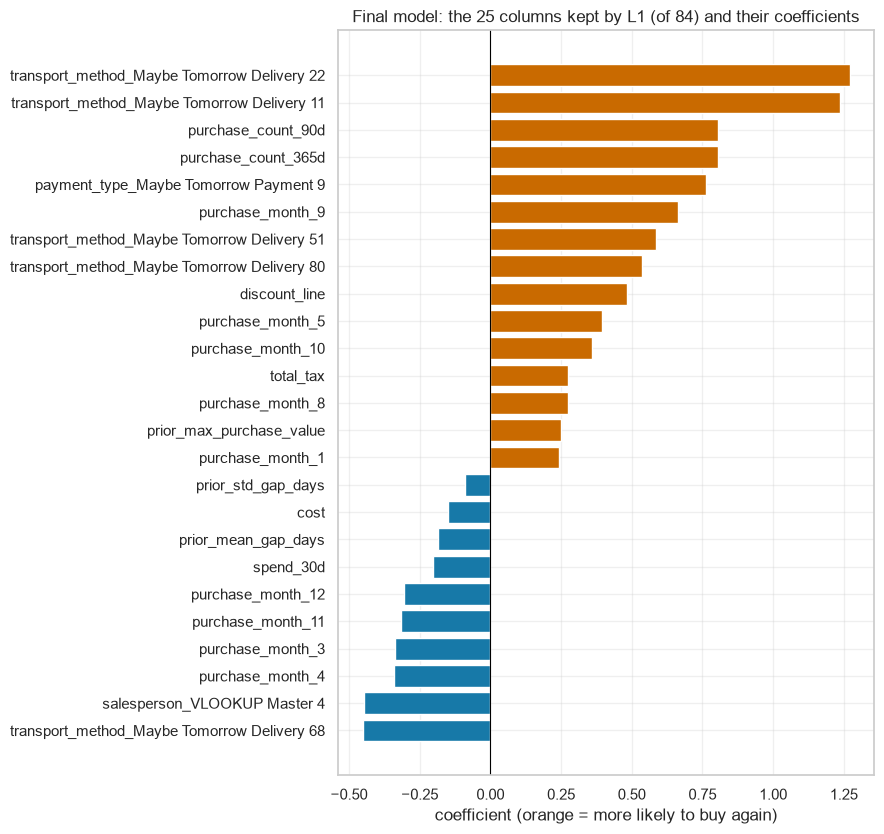

source columns with no encoded column kept (22 of 35): total_to_pay, total_gross, total_net, total_shipping, discount_global, n_lines, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, purchase_count_30d, spend_90d, purchase_count_180d, spend_180d, spend_365d, commercial_zone, warehouse, document_series


In [27]:
final_pipeline = pipeline(BASE_FEATURES, LogisticRegression(max_iter=2000),
                          select=SelectFromModel(scaled_l1(0.05), importance_getter=L1_COEF))
final_fit = clone(final_pipeline).fit(X_full, y)
encoded = np.array([n.split("__", 1)[1] for n in final_fit.named_steps["prep"].get_feature_names_out()])
kept = final_fit.named_steps["select"].get_support()
coefficients = pd.Series(final_fit.named_steps["model"].coef_[0], index=encoded[kept]).sort_values()

fig, ax = plt.subplots(figsize=(9, 0.3 * len(coefficients) + 1))
ax.barh(coefficients.index, coefficients, color=np.where(coefficients > 0, ORANGE, BLUE))
ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"Final model: the {kept.sum()} columns kept by L1 (of {len(kept)}) and their coefficients",
       xlabel="coefficient (orange = more likely to buy again)")
plt.tight_layout()
plt.show()
sources = BASE_FEATURES(X_full.head()).columns
unused = [c for c in sources if not any(e == c or e.startswith(f"{c}_") for e in encoded[kept])]
print(f"source columns with no encoded column kept ({len(unused)} of {len(sources)}):", ", ".join(unused))

L1 keeps one or two columns from each group of near-duplicates: tax, line discount and cost among the invoice totals; the maximum purchase and the mean and spread of the gaps from the history; `purchase_count_90d`, `purchase_count_365d` and `spend_30d` from the rolling windows. Two columns of the box plots in Section 1.6 are dropped as well, because kept columns repeat them: `days_since_previous_purchase` (Spearman −0.86 with `purchase_count_90d`) and `prior_purchase_count` (0.80 with `purchase_count_365d`). `commercial_zone`, `warehouse` and `document_series` are dropped entirely. The signs are what we would expect: recent purchase counts push towards a repeat (+0.80 each), a longer usual gap pushes away from it (−0.19), and the peak months March and November are negative while January, May and September are positive.

# 4. Model and performance assessment <a class="anchor" id="model"></a>
[Back to contents](#toc)

## 4.1 Why not random K-fold
Random folds mix past and future and put neighbouring purchases of the same customer on both sides of the split. The same two pipelines under both schemes:

In [28]:
random_folds = list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_full, y))
reference_model = pipeline(BASE_FEATURES, HistGradientBoostingClassifier(random_state=RANDOM_STATE), linear=False)
pd.DataFrame({
    "time CV + 90-day gap": [evaluate(final_pipeline)[0].mean(), evaluate(reference_model)[0].mean()],
    "random 5-fold": [evaluate(final_pipeline, random_folds)[0].mean(), evaluate(reference_model, random_folds)[0].mean()],
}, index=["logistic + L1 (final)", "gradient boosting"]).round(4)

,time CV + 90-day gap,random 5-fold
logistic + L1 (final),0.7958,0.7898
gradient boosting,0.7742,0.7932


With time-ordered folds the logistic regression is clearly ahead of gradient boosting (0.796 against 0.774). With random folds the order flips (0.790 against 0.793): the trees profit from later purchases and from neighbouring purchases of the same customer, which will never be available for the real test set.

## 4.2 Metrics
F1 is the competition metric, so it decides the threshold and the final choice. Pipelines are compared on ROC AUC, which does not depend on the threshold. Predicting 1 for every row already gives an F1 of about 0.75 on the last fold, and every model is reported against that floor. The honest F1 uses a threshold chosen on folds 1–2 and scored on fold 3, the fold closest in time to the test set.

## 4.3 Candidate models
The final pipeline against four algorithms without feature selection: logistic regression and gradient boosting with default settings, KNN with k = 25 and a decision tree of depth 6. All use the month feature and the pre-processing of Section 2.7.

In [29]:
early = np.concatenate([va for _, va in FOLDS[:-1]])
last = FOLDS[-1][1]
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)


def best_threshold(y_true, proba):
    """Threshold with the highest F1, plus the whole F1 curve."""
    curve = pd.Series([f1_score(y_true, proba >= t) for t in THRESHOLDS], index=THRESHOLDS)
    return curve.idxmax(), curve


def honest_f1(oof):
    """F1 on fold 3 at the threshold that maximises F1 on folds 1-2."""
    threshold, _ = best_threshold(y.iloc[early], oof.iloc[early])
    return f1_score(y.iloc[last], oof.iloc[last] >= threshold), threshold


models = {
    "logistic regression + L1 selection (final)": final_pipeline,
    "logistic regression": pipeline(BASE_FEATURES, LogisticRegression(max_iter=2000)),
    "KNN (k = 25)": pipeline(BASE_FEATURES, KNeighborsClassifier(n_neighbors=25)),
    "decision tree (depth 6)": pipeline(BASE_FEATURES, DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
                                        linear=False),
    "gradient boosting": reference_model,
}
board, oofs = {}, {}
for name, model in models.items():
    aucs, oofs[name] = evaluate(model)
    f1, t = honest_f1(oofs[name])
    board[name] = {"ROC AUC": aucs.mean(), "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in aucs),
                   "threshold (folds 1-2)": t, "honest F1 (fold 3)": f1}
floor = f1_score(y.iloc[last], np.ones(len(last)))
board = pd.DataFrame(board).T.assign(**{"F1 - floor": lambda b: b["honest F1 (fold 3)"] - floor})
board.style.format({"ROC AUC": "{:.4f}", "threshold (folds 1-2)": "{:.2f}", "honest F1 (fold 3)": "{:.3f}",
                    "F1 - floor": "{:+.3f}"})

,ROC AUC,fold 1 / 2 / 3,threshold (folds 1-2),honest F1 (fold 3),F1 - floor
logistic regression + L1 selection (final),0.7958,0.779 / 0.807 / 0.801,0.43,0.802,+0.049
logistic regression,0.7851,0.767 / 0.791 / 0.797,0.34,0.790,+0.037
KNN (k = 25),0.7758,0.773 / 0.772 / 0.782,0.41,0.780,+0.026
decision tree (depth 6),0.7465,0.720 / 0.737 / 0.782,0.41,0.765,+0.011
gradient boosting,0.7742,0.761 / 0.766 / 0.796,0.26,0.777,+0.023


The final pipeline is the best on both measures: ROC AUC 0.796 and honest F1 0.802, 0.049 above the floor. The same predictions scored 0.804 on the Kaggle public leaderboard. Most of the gain over the plain logistic regression comes from the L1 step (0.785 to 0.796). KNN and gradient boosting with default settings stay behind, and the single tree is the weakest and the least stable from year to year.

## 4.4 Threshold
The final threshold maximises F1 on the out-of-fold predictions of all three folds. The honest F1 above used folds 1–2 only, so it stays unbiased.

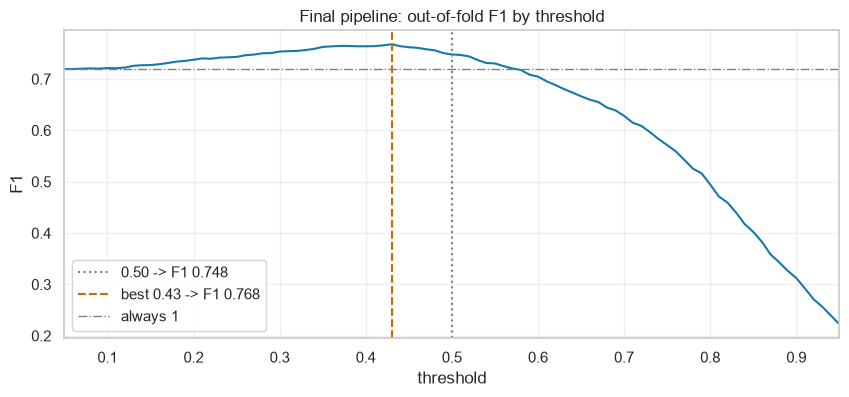

final threshold: 0.43 | honest F1 (fold 3): 0.802


In [30]:
final_oof = oofs["logistic regression + L1 selection (final)"]
covered = final_oof.notna()
FINAL_THRESHOLD, f1_curve = best_threshold(y[covered], final_oof[covered])

fig, ax = plt.subplots()
ax.plot(f1_curve.index, f1_curve.values, color=BLUE)
ax.axvline(0.5, color="grey", ls=":", label=f"0.50 -> F1 {f1_curve[0.5]:.3f}")
ax.axvline(FINAL_THRESHOLD, color=ORANGE, ls="--", label=f"best {FINAL_THRESHOLD:.2f} -> F1 {f1_curve[FINAL_THRESHOLD]:.3f}")
ax.axhline(f1_score(y[covered], np.ones(covered.sum())), color="grey", ls="-.", lw=1, label="always 1")
ax.set(title="Final pipeline: out-of-fold F1 by threshold", xlabel="threshold", ylabel="F1", xlim=(0.05, 0.95))
ax.legend()
plt.show()
print(f"final threshold: {FINAL_THRESHOLD:.2f} | honest F1 (fold 3): {honest_f1(final_oof)[0]:.3f}")

The best threshold is 0.43 rather than 0.5: with 56% of purchases being repeats, F1 favours predicting 1 more readily. The curve is flat between about 0.36 and 0.46, so the exact value matters little.

## 4.5 Final model and predictions
The pipeline is refitted on all clean training rows and the threshold turns the test probabilities into labels. IDs are kept as in `sample_submission.csv`.

In [31]:
final_model = clone(final_pipeline).fit(X_full, y)
proba_test = final_model.predict_proba(X_test_full)[:, 1]
submission = pd.DataFrame({"ID": X_test_full.index, TARGET: (proba_test >= FINAL_THRESHOLD).astype(int)})

# Same columns and IDs, in the same order, as sample_submission.csv, and only 0/1 labels
assert (list(submission.columns) == list(sample.columns)
        and submission["ID"].reset_index(drop=True).equals(sample["ID"])
        and submission[TARGET].isin([0, 1]).all())

submission.to_csv(OUTPUT, index=False)
print(f"{len(submission)} predictions written to {OUTPUT.name}: {submission[TARGET].mean():.1%} predicted 1")
submission.head()

986 predictions written to Homework_Group41_submission.csv: 73.6% predicted 1


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1
